# Task 4 · Reconstruct the Flight (20 marks)

Connect your trackers to the provided pipeline and recover the lander's
velocity and 3D trajectory, then find out how the quality of your optical flow
decides the result. You write only the four short functions of Task 4.1; the
camera-motion fit (`provided/task4/motion_model.py`), the flight code
(`provided/task4/trajectory.py`) and the plots are provided.

The camera points straight down at flat ground. As the lander moves, the
tracked ground features between two consecutive frames undergo a similarity:
they scale, rotate and translate,

$$
\mathbf{x}_{k+1} = s_k R(\theta_k)\,\mathbf{x}_k + \mathbf{t}_k,
\qquad s_k = \frac{Z_k}{Z_{k+1}}.
$$

The provided fit estimates $s_k$, $\theta_k$ and $\mathbf{t}_k$ by robust least
squares, and the flight code turns them into altitude, position, velocity and
the 3D trajectory, in metres and seconds. The world frame is fixed to frame
270: $X$ to the right, $Y$ toward its top (image $y$ points down), $Z$ the
altitude (up).

**How this notebook works**

* Write your code only in the cells whose first line starts with `# YOUR CODE`.
  Only those cells are graded, and they are read from the **saved** notebook.
  Add your own cells anywhere for experiments or notes: they are never graded.
  A helper function you want graded with your code goes in a `# YOUR CODE` cell
  (a new cell whose first line is `# YOUR CODE` works too).
* Run the `check(...)` cell after your code: it tests your functions and prints
  PASS or FAIL for each test.
* Answer each question in the cell right below it, in one or two sentences,
  replacing *TODO*.
* Save often (Ctrl+S). Before you submit, run everything from a clean start:
  restart the kernel and run all cells, or run `python run_notebooks.py`.

In [6]:
# PROVIDED: run this cell first (save task3.ipynb before)
%matplotlib inline
import numpy as np
from provided.notebook import check, use_my_functions
from provided.sift import sift_matches, track_with_sift
from provided.task4.compare_trackers import compare
from provided.task4.run import read_motion, reconstruct_flight

use_my_functions(3)               # your Task 1 to 3 functions, from the saved notebooks

your functions from task1.ipynb, task2.ipynb, task3.ipynb (the saved files): spatial_gradients, temporal_difference, structure_tensor, feature_score, select_features, lucas_kanade_update, one_step_flow, track_point, track_points


## 4.1 Connect your trackers to the pipeline (4 marks)

Fill in the three adapters `one_step`, `iterative` and `sift_guided`, which
call your Task 3 `track_points`, and `track_pair`, which selects points
(Task 1.3), runs one tracker and keeps the valid tracks. A tracker is a
function `(image0, image1, points) -> (tracked, valid)`.

In [7]:
# YOUR CODE: Task 4.1

# the settings every tracker uses (keep them for the reference numbers)
MAX_POINTS = 200
FEATURE_RADIUS = 3
MIN_DISTANCE = 10
TRACK_RADIUS = 7
ITERATIONS = 10

def one_step(image0, image1, points):
    """One Lucas-Kanade update per point (the Task 2 method).

    Hint: return track_points(image0, image1, points, TRACK_RADIUS, max_iterations=1),
    so it uses the same windows and checks as `iterative` below.
    """
    return track_points(image0, image1, points, TRACK_RADIUS, max_iterations=1)


def iterative(image0, image1, points):
    """Iterative Lucas-Kanade per point (Task 3).

    Hint: track_points with TRACK_RADIUS and max_iterations=ITERATIONS.
    """
    return track_points(image0, image1, points, TRACK_RADIUS, max_iterations=ITERATIONS)


def sift_guided(image0, image1, points):
    """Iterative Lucas-Kanade started from SIFT guesses (Task 3.3).

    Hint: matches = sift_matches(image0, image1), then
    track_with_sift(track_points, image0, image1, points, matches, TRACK_RADIUS,
    max_iterations=ITERATIONS).
    """
    return track_with_sift(track_points, image0, image1, points, sift_matches(image0, image1), TRACK_RADIUS, max_iterations=ITERATIONS)

def track_pair(image0, image1, tracker):
    """Select points in image0 and track them into image1 with `tracker`.

    Returns (points0, points1), keeping only the valid tracks.

    Hint: points = select_features(image0, MAX_POINTS, FEATURE_RADIUS, MIN_DISTANCE),
    then tracked, valid = tracker(image0, image1, points); return both arrays
    indexed with valid.
    """
    points0_all = select_features(image0, MAX_POINTS, FEATURE_RADIUS, MIN_DISTANCE)
    
    # 2. Track the N features into the second image
    # tracked_all has shape (N, 2), valid_mask has shape (N,)
    tracked_all, valid_mask = tracker(image0, image1, points0_all)
    
    # 3. Apply the boolean mask to BOTH arrays to maintain 1:1 correspondence
    # The resulting arrays will both have shape (M, 2)
    points0_valid = points0_all[valid_mask]
    points1_valid = tracked_all[valid_mask]
    
    return points0_valid, points1_valid

In [8]:
check("4.1")

trackers = {"one-step": one_step, "iterative": iterative, "sift-guided": sift_guided}

Task 4.1 checks
  PASS  one step tracks a small shift
  PASS  iterative tracks a larger shift
  PASS  sift guided beats one step on large motion
  PASS  track pair selects and tracks points
4 of 4 passed


**(a)** Why must `track_pair` drop the failed tracks before the motion fit?

Failed tracks may be incorrect correspondences, so including them can bias the fitted scale, rotation, and translation. `track_pair` must pass only valid, matched point pairs to the motion fit.


## 4.2 Read the motion from the images (4 marks)

The provided cell tracks all 143 frame pairs with your SIFT-guided tracker
(a few minutes), fits the camera motion of every pair and plots the zoom,
rotation and shift.

tracking 143 pairs with the sift-guided tracker (a few minutes)
  270 to 271: 181 tracks
  290 to 291: 171 tracks
  310 to 311: 173 tracks
  330 to 331: 193 tracks
  350 to 351: 160 tracks
  370 to 371: 189 tracks
  390 to 391: 171 tracks
  410 to 411: 152 tracks
  412 to 413: 136 tracks
  saved outputs/task4/motion.csv (143 pairs)
  saved outputs/task4/zoom.png


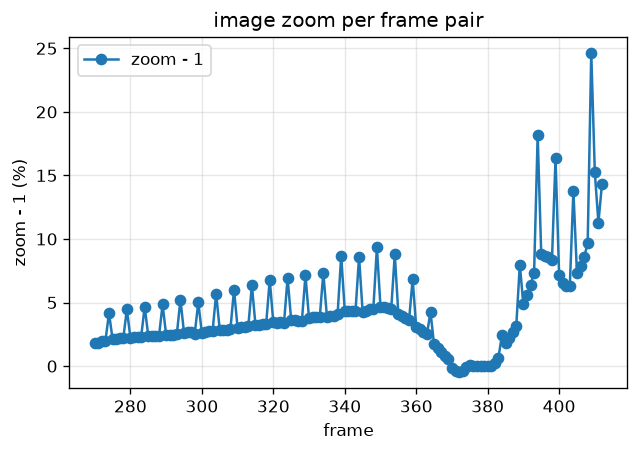

  saved outputs/task4/rotation.png


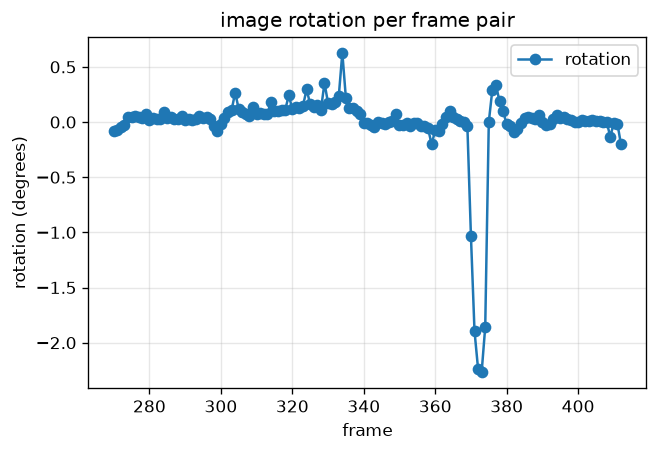

  saved outputs/task4/shift.png


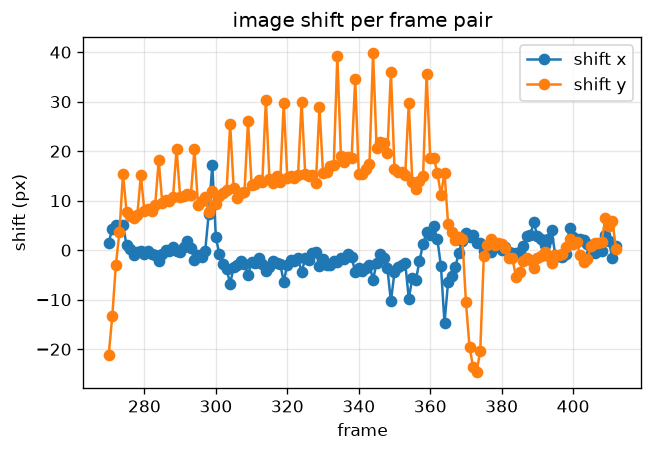

In [9]:
motion = read_motion(track_pair, trackers["sift-guided"])

**(a)** Why is the zoom $s_k = Z_k / Z_{k+1}$? Use the pinhole model.

For a downward-looking pinhole camera, a ground point's image coordinate relative to the principal point is proportional to $1/Z$: $x = \frac{fX}{Z}$. Thus the image scale between frames is $(1/Z_{k+1})/(1/Z_k) = Z_k/Z_{k+1} = s_k$.

**(b)** What are the phases of the descent, and at about which frames do they change?

The plots suggest an initial descent from about frames 270–370, a near-hover/braking phase around frames 370–385 (zoom near zero), and a final descent from roughly frame 386 to 413 as zoom rises again. These frame boundaries are approximate.


**(c)** Which pattern in these plots is not caused by the lander, and how can you tell?

The repeated alternating spikes in zoom and vertical shift are unlikely to be real lander motion: they appear in a regular every-other-pair pattern on top of a smoother trend, suggesting tracking or motion-fit artifacts. 


## 4.3 Reconstruct the flight (4 marks)

The provided cell turns the motion into the altitude, the velocity
$(v_X, v_Y, v_Z)$, the time to touchdown $\tau = Z / (-v_Z)$, the 3D trajectory
and the ground track (seen from above, $X$ to the right and $Y$ up).

  saved outputs/task4/altitude.png


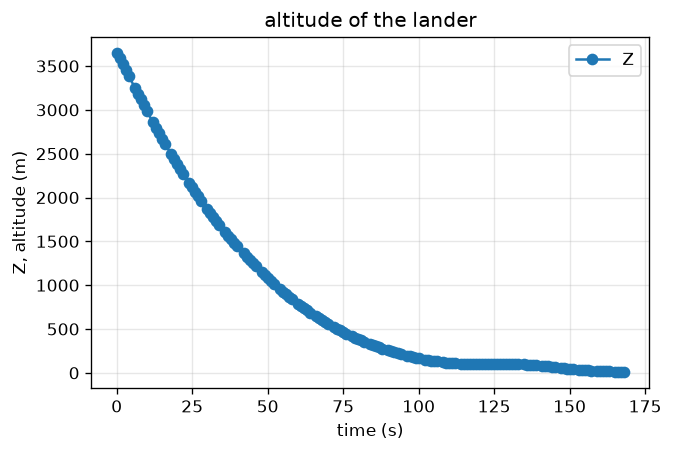

  saved outputs/task4/velocity.png


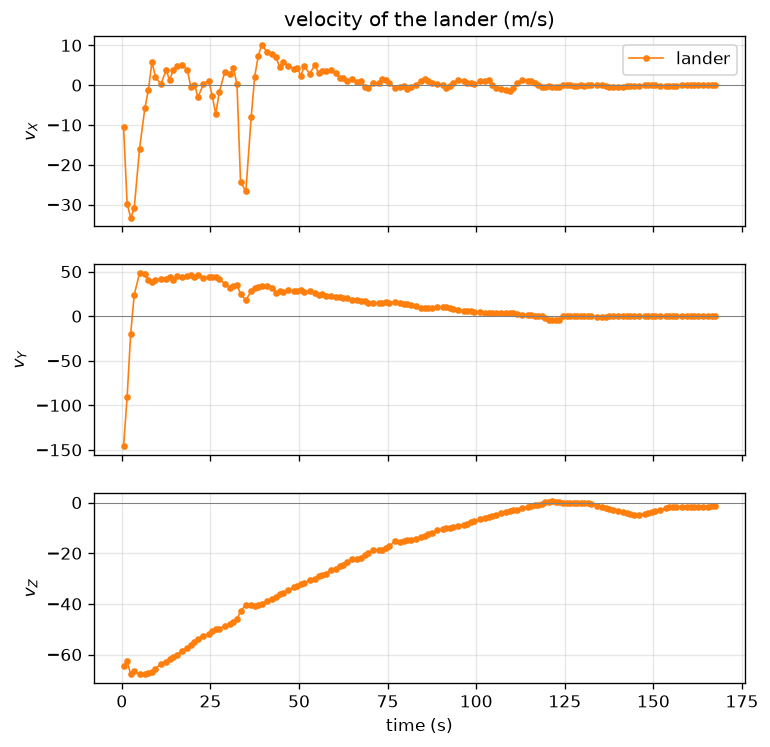

  saved outputs/task4/time_to_touchdown.png


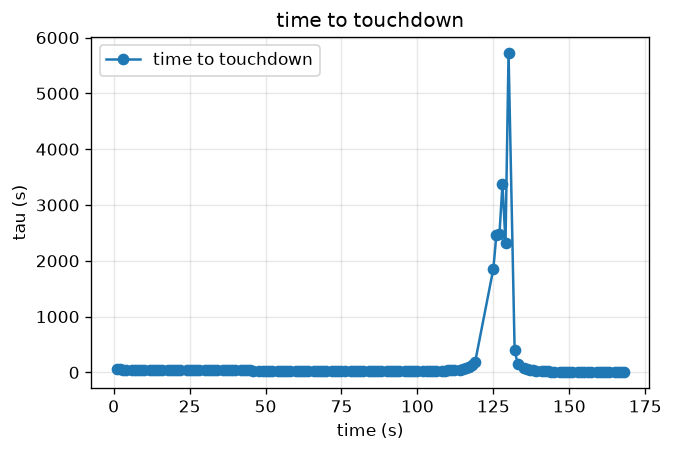

  saved outputs/task4/trajectory_3d.png


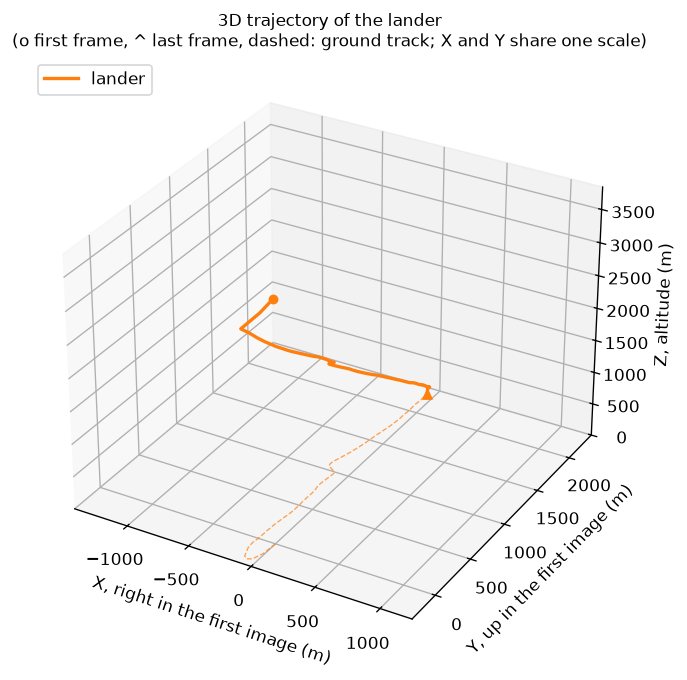

  saved outputs/task4/ground_track.png


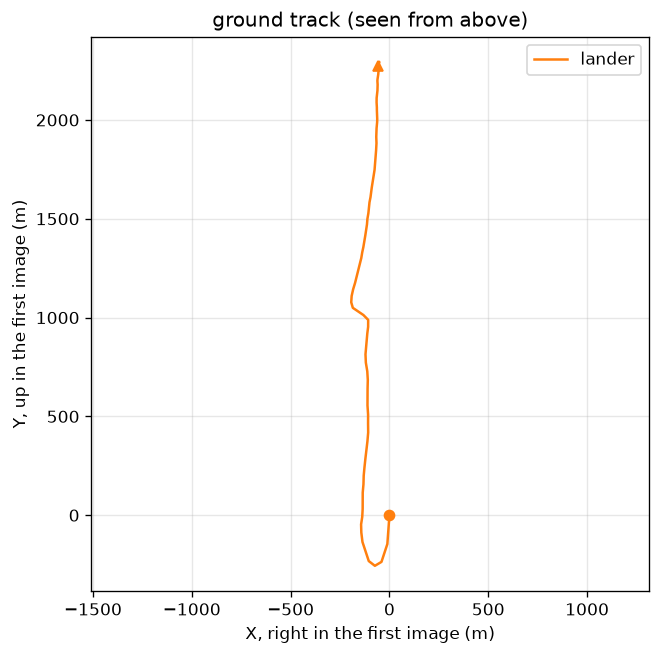

  saved outputs/task4/summary.json
  summary: frames [270, 413], length_unit m, time_unit s, start_Z 3650, end_Z 9.112, duration 168, horizontal_drift 2273, max_descent_speed 67.83


In [10]:
flight, summary = reconstruct_flight(motion)

**Table.** Fill in the numbers printed above (also in `outputs/task4/summary.json`).

| Quantity | Value |
|----------|-------|
| Start and end altitude Z | 3650 m → 9.112 m |
| Duration | 168 s |
| Largest descent speed | 67.83 m/s |
| Horizontal drift | 2273 m |


**(a)** Which result do you trust least, and why?

I trust the time-to-touchdown estimate least near the hover phase. Since `τ = Z / (-v_Z)`, when vertical speed approaches zero the estimate becomes unstable and spikes to thousands of seconds, which is not a meaningful prediction.


## 4.4 Compare the three trajectories (5 marks)

The provided cell runs the whole pipeline once per tracker on the same points
and draws the three ground tracks together (several minutes the first time;
the tracks are saved and reused while your code stays the same).

tracking 143 pairs with 3 trackers (several minutes)
  270 to 271: tracks kept: one-step 188, iterative 186, sift-guided 181
  290 to 291: tracks kept: one-step 184, iterative 181, sift-guided 171
  310 to 311: tracks kept: one-step 188, iterative 187, sift-guided 173
  330 to 331: tracks kept: one-step 198, iterative 196, sift-guided 193
  350 to 351: tracks kept: one-step 186, iterative 184, sift-guided 160
  370 to 371: tracks kept: one-step 184, iterative 184, sift-guided 189
  390 to 391: tracks kept: one-step 188, iterative 188, sift-guided 171
  410 to 411: tracks kept: one-step 189, iterative 189, sift-guided 152
  412 to 413: tracks kept: one-step 192, iterative 191, sift-guided 136
  saved outputs/task4/compare/ground_track.png


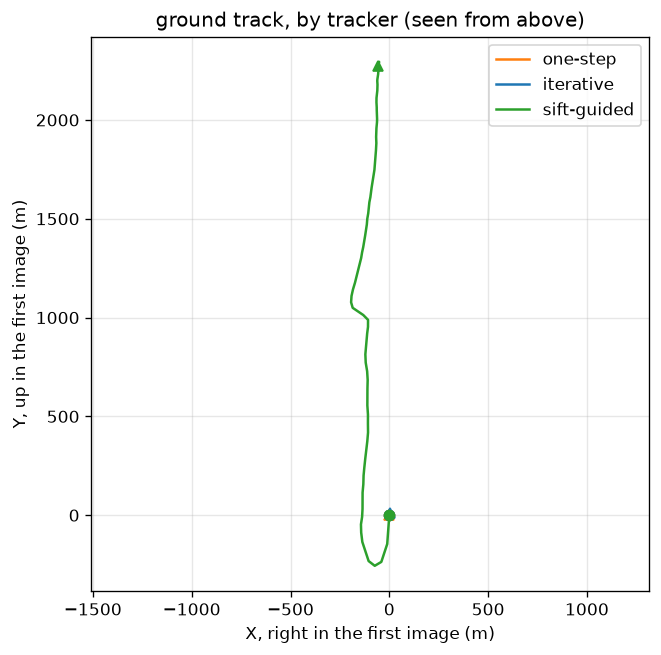

  saved outputs/task4/compare/summary.csv
      one-step: end Z 99.01 m, drift 1.312 m, median residual 0.23 px
     iterative: end Z 92.91 m, drift 8.8 m, median residual 1.80 px
   sift-guided: end Z 9.112 m, drift 2273 m, median residual 0.34 px


In [11]:
table = compare(trackers, track_pair)

**Table.** Fill in the numbers printed above (also in `outputs/task4/compare/summary.csv`).

| Tracker | End altitude | Horizontal drift | Median residual |
|---------|--------------|------------------|-----------------|
| one-step | 99.01 m | 1.312 m | 0.23 px |
| iterative | 92.91 m | 8.8 m | 1.80 px |
| SIFT-guided | 9.112 m | 2273 m | 0.34 px |


**(a)** Which trajectory do you trust, and which Task 3 result supports it?

Of these, SIFT-guided best recovers the overall descent altitude, ending at 9.112 m rather than about 93–99 m for the other trackers. Task 3.4 supports this for large motion: on frames 300→301 SIFT-guided estimates 9.98 px, versus 2.38 px iterative and 0.29 px one-step, although its high touchdown failure rate means its horizontal drift should be treated cautiously.


**(b)** Does a low median residual mean a tracker is right? Use your numbers.

No. Median residual measures agreement with the fitted similarity model, not whether the correspondences are physically correct. For example, one-step has the lowest residual (0.23 px) but ends at 99.01 m, while SIFT-guided ends at 9.112 m with a 0.34 px residual and a much larger 2273 m drift; a low residual alone does not establish accuracy.


Optional, not graded: the next cell writes
`outputs/task4/trajectory_animation.html`, the three flights as an interactive
3D animation to open in a web browser.

In [1]:
!pip install plotly
from provided.task4.animate_trajectory import main as animate
animate([])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 291.0 kB/s  0:00:32 eta 0:00:01

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
  saved /Users/d0lph1n/WorkSpace/GitHubRepos/ComputerVision-Course/Assignment03/outputs/task4/trajectory_animation.html  (open it in a web browser)
done


## 4.5 Where does uncertainty come from? (3 marks)

**(a)** Why does a small error in each zoom grow along the descent?

Altitude is reconstructed by multiplying the per-frame scale ratios: `Z_n = Z_0 / (s_0 s_1 ... s_{n-1})`. Small biases therefore compound over many frame pairs, and finite differences can further amplify altitude noise in the velocity and trajectory estimates.


**(b)** What changes if the anchor altitude is 10 % too high? And if the focal length is?

If the anchor altitude is 10% too high, reconstructed altitudes and metric displacements/velocities are approximately 10% too high (for example, 3650 m becomes 4015 m and 2273 m drift becomes about 2500 m); duration is unchanged. If focal length is 10% too high, horizontal metric positions and drift become about `1/1.1 ≈ 0.909` of their correct values, while zoom-derived altitude is largely unchanged.


# Final Mission Report · What Did We Learn? (bonus, 5 marks)

One or two sentences each, with one piece of evidence from your results.

**Q1.** Where in the descent does "all pixels in a window move together" fail most, and what in your results shows it?

The constant-motion assumption is most strained near touchdown, frames 409→410, when apparent motion and scale change rapidly. Task 3.4 shows SIFT-guided tracking has a 0.60 failed-track rate and a mean displacement of 32.74 px there, indicating that many correspondences are difficult to track reliably.


**Q2.** Would a pyramidal (coarse-to-fine) KLT tracker fix 300 to 301? Would it fix 409 to 410? Why?

A pyramidal KLT tracker would likely help on 300→301 by reducing a large displacement to a smaller motion at coarse scales, but it would not guarantee correct matches. It would not fix 409→410, where the 0.60 SIFT-guided failure rate suggests correspondence, scale-change, or out-of-frame problems that pyramids alone cannot solve.


**Q3.** If you ignored the pattern from Task 4.2, which Task 4.3 results would be wrong, and by how much?

The alternating zoom and shift spikes can affect the altitude and vertical velocity estimates. Errors in the shifts can also affect horizontal position, drift, and velocity.

The results show how sensitive the reconstruction is to tracking quality: the ending altitude ranges from 9.112 to 99.01 m, while horizontal drift ranges from 1.312 to 2273 m across the three trackers. These differences show that tracking errors can have a large impact on the estimated flight.

**Q4.** Where does the "flat ground, camera straight down" model fail, and what error does it cause?

The model fails where the surface is not planar or the camera is not exactly pointing straight down. crater relief and camera attitude changes create perspective effects that a single scale–rotation–translation transform cannot fully describe. The fit can then mistake terrain or rotation effects for lander translation or altitude change.


**Q5.** Name one independent measurement that would check your trajectory, and what it would check.

An independent altitude reading at a known frame would check the reconstructed altitude against a direct range measurement. Comparing several readings across the descent would test the altitude scale and the inferred vertical motion.


# References

List every source you used, including the Chang'e-5 landing camera data (level 2A, https://moon.bao.ac.cn).

- Chang'e-5 landing-camera imagery, level 2A data, lunar data portal: https://moon.bao.ac.cn
- Lucas, B. D., & Kanade, T. (1981). “An Iterative Image Registration Technique with an Application to Stereo Vision.” IJCAI.
- Shi, J., & Tomasi, C. (1994). “Good Features to Track.” IEEE Conference on Computer Vision and Pattern Recognition.
- Lowe, D. G. (2004). “Distinctive Image Features from Scale-Invariant Keypoints.” *International Journal of Computer Vision*, 60, 91–110.


Special Citation
- Torralba, A., Isola, P., & Freeman, W. T. (2024). Foundations of Computer Vision. MIT Press. See Chapter 47, “3D Motion and Its 2D Projection,” and Chapter 48, “Optical Flow Estimation.” Online textbook.